<a href="https://colab.research.google.com/github/Storm00212/Signals-and-communication-visualisation/blob/main/Signals_revision_Q4_signals_practice_questions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# ---- Parameters ----
Fs = 1000.0          # sampling rate, Hz
T_total = 5.0         # seconds, t in [0,5]
dt = 1/Fs
t = np.arange(0, T_total, dt)
N = len(t)
print(f"N = {N} samples, dt = {dt} s")

N = 5000 samples, dt = 0.001 s


In [4]:
# ---- Generate x(t) = exp(-2t) u(t) ----
x = np.exp(-2*t)

# ---- Energy of x(t) directly from time samples ----
Ex_time = np.sum(np.abs(x)**2) * dt
print(f"Energy of x(t) from time-domain samples: Ex = {Ex_time:.6f} (theory: 0.25)")

Energy of x(t) from time-domain samples: Ex = 0.250500 (theory: 0.25)


In [5]:
# ---- FFT ----
X = np.fft.fft(x)
freqs = np.fft.fftfreq(N, d=dt)   # includes negative frequencies (not yet shifted)

In [6]:
# ---- Cutoff frequency computed analytically in part (a) ----
fc = np.tan(0.45*np.pi) / np.pi
print(f"Cutoff frequency fc = {fc:.4f} Hz")

# ---- Apply ideal LPF mask: zero out all FFT bins where |f| > fc ----
mask = (np.abs(freqs) <= fc).astype(float)
Y = X * mask

# ---- Inverse FFT to get filtered time-domain signal y(t) ----
y = np.fft.ifft(Y)
y_real = np.real(y)   # should be (numerically) real since x(t) is real and mask is symmetric

# ---- Energy of y(t) via sum of squared samples (Parseval check) ----
Ey_time = np.sum(np.abs(y_real)**2) * dt
print(f"Energy of y(t) from time-domain samples: Ey = {Ey_time:.6f}")
print(f"Ratio Ey/Ex = {Ey_time/Ex_time:.4f}  (target: 0.90)")

# ---- Also verify via Parseval directly in frequency domain (sum |Y|^2 / N / Fs convention check) ----
Ex_freq = np.sum(np.abs(X)**2) * dt / N
Ey_freq = np.sum(np.abs(Y)**2) * dt / N
print(f"[Frequency-domain Parseval check] Ex = {Ex_freq:.6f}, Ey = {Ey_freq:.6f}, ratio = {Ey_freq/Ex_freq:.4f}")


Cutoff frequency fc = 2.0097 Hz
Energy of y(t) from time-domain samples: Ey = 0.226531
Ratio Ey/Ex = 0.9043  (target: 0.90)
[Frequency-domain Parseval check] Ex = 0.250500, Ey = 0.226531, ratio = 0.9043


FileNotFoundError: [Errno 2] No such file or directory: '/mnt/user-data/outputs/q4_lpf_simulation.png'

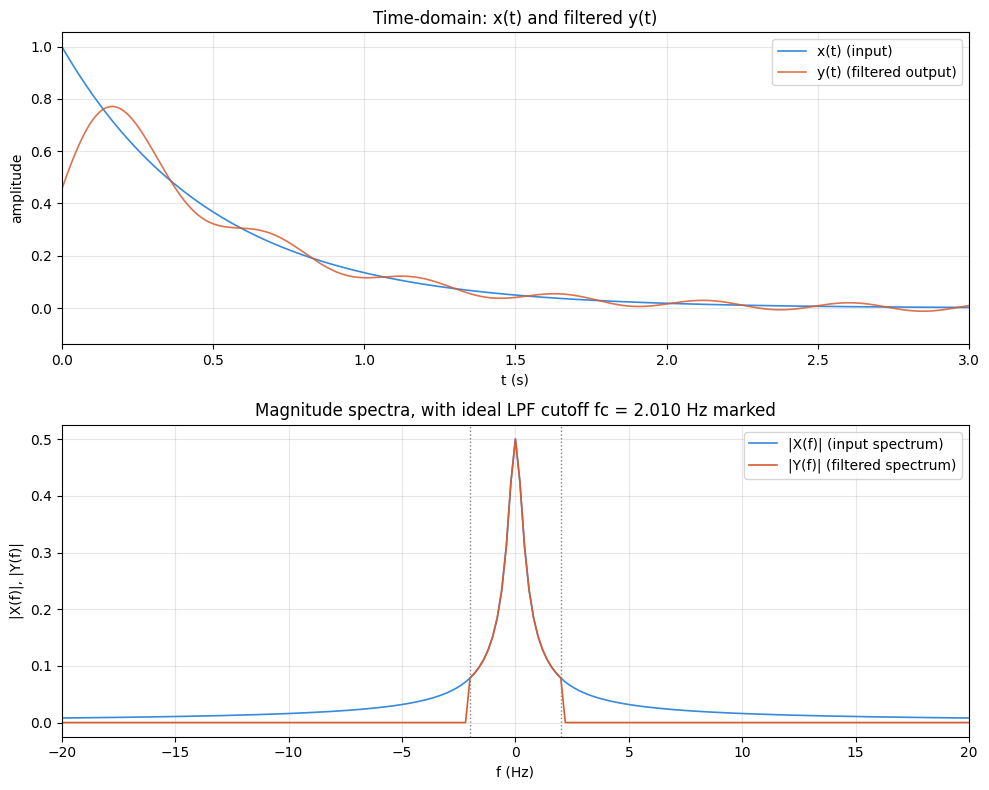

In [7]:
# ---- Plot ----
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].plot(t, x, label="x(t) (input)", color="#378ADD", linewidth=1.2)
axes[0].plot(t, y_real, label="y(t) (filtered output)", color="#D85A30", linewidth=1.2, alpha=0.85)
axes[0].set_xlabel("t (s)")
axes[0].set_ylabel("amplitude")
axes[0].set_title("Time-domain: x(t) and filtered y(t)")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[0].set_xlim(0, 3)

freqs_shift = np.fft.fftshift(freqs)
X_shift = np.fft.fftshift(X)
Y_shift = np.fft.fftshift(Y)
axes[1].plot(freqs_shift, np.abs(X_shift)*dt, label="|X(f)| (input spectrum)", color="#378ADD", linewidth=1.2)
axes[1].plot(freqs_shift, np.abs(Y_shift)*dt, label="|Y(f)| (filtered spectrum)", color="#D85A30", linewidth=1.2)
axes[1].axvline(fc, color='gray', linestyle=':', linewidth=1)
axes[1].axvline(-fc, color='gray', linestyle=':', linewidth=1)
axes[1].set_xlim(-20, 20)
axes[1].set_xlabel("f (Hz)")
axes[1].set_ylabel("|X(f)|, |Y(f)|")
axes[1].set_title(f"Magnitude spectra, with ideal LPF cutoff fc = {fc:.3f} Hz marked")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
print("Saved plot.")